# 🐜🐝 Sesiunea 19 · Transfer learning pe un set de date propriu

**Povestea de azi:** avem doar **~250 de poze** cu furnici și albine. Prea puține ca să antrenăm un CNN de la zero. Dar putem „împrumuta” ce a învățat ResNet18 pe 1,2 milioane de poze și să-l **adaptăm** la clasele noastre.

Exact asta veți face la **proiectul 2**: setul vostru de poze, clasele voastre, un model celebru adaptat. La final ai un **șablon** pe care îl copiezi în proiect.

## Pregătire (rulează o dată)

In [1]:
import io, os, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
from torchvision import datasets, transforms, models
plt.rcParams["figure.figsize"] = (8, 4.5)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Rulăm pe:", device)

# ⚙️ Două funcții ajutătoare: le folosim ca pe .fit() și .score() din sklearn
def antreneaza(model, train_loader, epoci=1, lr=1e-3, val_loader=None):
    """Arată modelului datele de `epoci` ori și îl corectează după fiecare lot (batch)."""
    model.to(device)
    parametri = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(parametri, lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    for epoca in range(1, epoci + 1):
        model.train()
        total = corecte = 0
        suma_loss = 0.0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            iesire = model(x)
            loss = loss_fn(iesire, y)
            loss.backward()
            optimizer.step()
            suma_loss += loss.item() * len(y)
            corecte += (iesire.argmax(1) == y).sum().item()
            total += len(y)
        acc_train = corecte / total
        mesaj = f"epoca {epoca}: loss {suma_loss / total:.3f} | acuratețe train {acc_train:.3f}"
        if val_loader is not None:
            mesaj += f" | acuratețe validare {evalueaza(model, val_loader)[0]:.3f}"
        print(mesaj)
    return model

@torch.no_grad()
def evalueaza(model, loader):
    """Întoarce (acuratețe, etichete reale, predicții)."""
    model.to(device).eval()
    y_true, y_pred = [], []
    for x, y in loader:
        y_pred += model(x.to(device)).argmax(1).cpu().tolist()
        y_true += y.tolist()
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return (y_true == y_pred).mean(), y_true, y_pred

def incarca_imagine(sursa):
    """Deschide o imagine dintr-un URL sau dintr-un fișier local."""
    if str(sursa).startswith("http"):
        raspuns = requests.get(sursa, timeout=30)
        raspuns.raise_for_status()
        return Image.open(io.BytesIO(raspuns.content)).convert("RGB")
    return Image.open(sursa).convert("RGB")

MEDIE, DEVIATIE = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]     # normalizarea ImageNet

def arata_tensor(x, ax, titlu=""):
    """Afișează un tensor normalizat [3, H, W] ca imagine."""
    img = x.permute(1, 2, 0).numpy() * DEVIATIE + MEDIE
    ax.imshow(np.clip(img, 0, 1))
    ax.set_title(titlu, fontsize=9)
    ax.axis("off")

Rulăm pe: cuda


## 1 · Un set de date propriu = foldere 📁
*(după slide-ul „Cum organizezi pozele”)*

Cel mai simplu format: **un folder pentru fiecare clasă**, separat în `train` și `val`. Numele folderului **este** eticheta.

In [2]:
import zipfile
if not os.path.exists("hymenoptera_data"):
    raspuns = requests.get("https://download.pytorch.org/tutorial/hymenoptera_data.zip", timeout=120)
    raspuns.raise_for_status()
    zipfile.ZipFile(io.BytesIO(raspuns.content)).extractall(".")

for impartire in ["train", "val"]:
    for clasa in sorted(os.listdir(f"hymenoptera_data/{impartire}")):
        n = len(os.listdir(f"hymenoptera_data/{impartire}/{clasa}"))
        print(f"hymenoptera_data/{impartire}/{clasa}/   {n} poze")

hymenoptera_data/train/ants/   124 poze
hymenoptera_data/train/bees/   121 poze
hymenoptera_data/val/ants/   70 poze
hymenoptera_data/val/bees/   83 poze


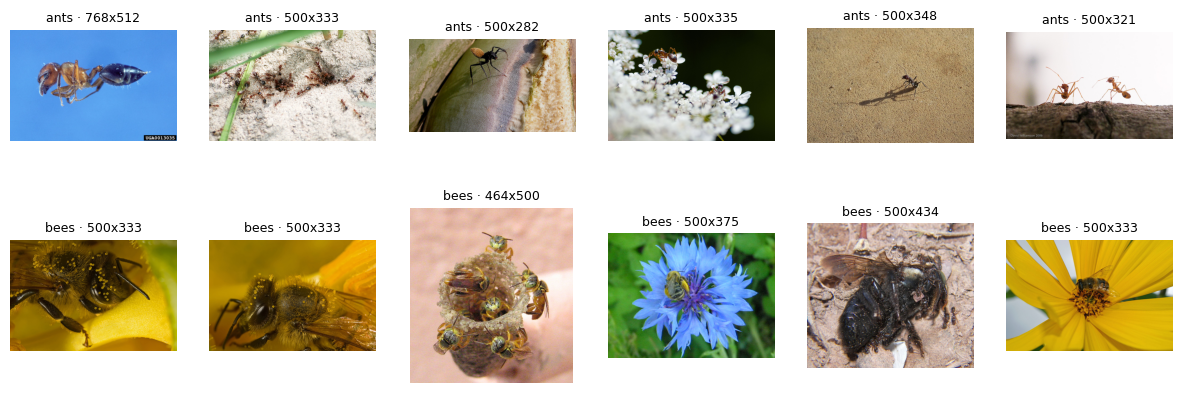

In [3]:
fig, axe = plt.subplots(2, 6, figsize=(15, 5))
for rand, clasa in enumerate(["ants", "bees"]):
    fisiere = sorted(os.listdir(f"hymenoptera_data/train/{clasa}"))[:6]
    for ax, f in zip(axe[rand], fisiere):
        img = Image.open(f"hymenoptera_data/train/{clasa}/{f}")
        ax.imshow(img)
        ax.set_title(f"{clasa} · {img.size[0]}x{img.size[1]}", fontsize=9)
        ax.axis("off")
plt.show()

**🤔 Întrebare** · Observă mărimile pozelor (titlurile). Ce probleme vezi pentru un model care vrea `[3, 224, 224]`? Și cum ți-ai organiza **tu** pozele pentru un proiect cu 3 clase?

> ✍️ *Răspunsul tău:* ....

## 2 · De la poze la tensori: transformări și augmentare 🔄
*(după slide-ul „Augmentare”)*

- **Validare**: doar aducem poza la formatul cerut de ResNet (mărime 224, normalizare ImageNet).
- **Antrenare**: în plus, o **modificăm puțin la întâmplare** la fiecare epocă (tăiem, întoarcem). Modelul vede mereu variante noi, ca și cum am avea mai multe date.

In [4]:
transform_train = transforms.Compose([
    transforms.RandomResizedCrop(224),          # o bucată aleatoare din poză, adusă la 224x224
    transforms.RandomHorizontalFlip(),          # oglindire stânga-dreapta, 50% din timp
    transforms.ToTensor(),
    transforms.Normalize(MEDIE, DEVIATIE),
])
transform_val = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(MEDIE, DEVIATIE),
])

date_train = datasets.ImageFolder("hymenoptera_data/train", transform=transform_train)
date_val = datasets.ImageFolder("hymenoptera_data/val", transform=transform_val)
CLASE = date_train.classes
print("clase:", CLASE, "| etichete:", date_train.class_to_idx)
print("train:", len(date_train), "| val:", len(date_val))

train_loader = torch.utils.data.DataLoader(date_train, batch_size=16, shuffle=True)
val_loader = torch.utils.data.DataLoader(date_val, batch_size=32)
x, y = next(iter(train_loader))
print("un lot:", tuple(x.shape), "| etichete:", y.tolist())

clase: ['ants', 'bees'] | etichete: {'ants': 0, 'bees': 1}
train: 244 | val: 153
un lot: (16, 3, 224, 224) | etichete: [0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0]


**Exercițiul 2.1 · Vezi augmentarea**

Rulează celula de mai multe ori: aceeași poză arată de fiecare dată altfel. Apoi adaugă în `transform_demo` o transformare nouă, de exemplu `transforms.ColorJitter(brightness=0.5)` sau `transforms.RandomRotation(30)`. Ce augmentări **n-ar** avea sens pentru proiectul tău?

> ✍️ *Răspunsul tău:* ....

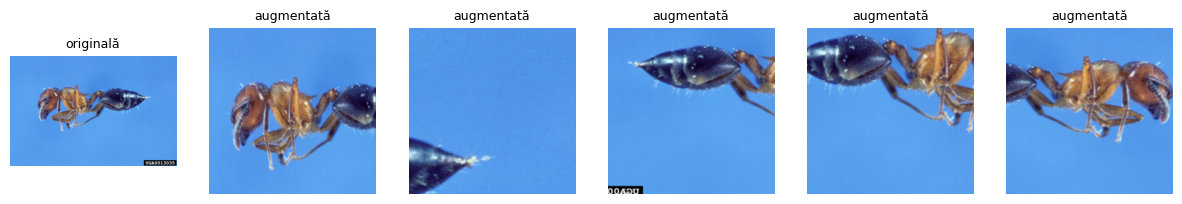

In [5]:
transform_demo = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    # ✏️ adaugă aici: transforms.ColorJitter(brightness=0.5), transforms.RandomRotation(30), ...
    transforms.ToTensor(),
    transforms.Normalize(MEDIE, DEVIATIE),
])
poza = Image.open(date_train.imgs[0][0]).convert("RGB")
fig, axe = plt.subplots(1, 6, figsize=(15, 3))
axe[0].imshow(poza); axe[0].set_title("originală", fontsize=9); axe[0].axis("off")
for ax in axe[1:]:
    arata_tensor(transform_demo(poza), ax, "augmentată")
plt.show()

### Varianta B: etichetele sunt într-un fișier CSV
Uneori datele vin altfel: toate pozele într-un folder și un tabel `fisier, eticheta`. Atunci scriem un **Dataset propriu**: o clasă mică care spune PyTorch-ului (1) câte exemple are și (2) cum citește exemplul cu numărul `i`.

In [6]:
# Construim un CSV de exemplu din aceleași poze (în proiect, CSV-ul îl ai deja)
tabel = pd.DataFrame([{"fisier": cale, "eticheta": CLASE[et]} for cale, et in date_val.imgs])
tabel.to_csv("etichete_val.csv", index=False)
display(tabel.sample(3, random_state=0))

class DatasetDinCSV(torch.utils.data.Dataset):
    def __init__(self, cale_csv, transform):
        self.tabel = pd.read_csv(cale_csv)
        self.clase = sorted(self.tabel["eticheta"].unique())
        self.transform = transform
    def __len__(self):                                   # câte exemple avem
        return len(self.tabel)
    def __getitem__(self, i):                            # cum citim exemplul cu numărul i
        rand = self.tabel.iloc[i]
        img = Image.open(rand["fisier"]).convert("RGB")
        return self.transform(img), self.clase.index(rand["eticheta"])

date_csv = DatasetDinCSV("etichete_val.csv", transform_val)
x0, y0 = date_csv[0]
print("exemple:", len(date_csv), "| primul exemplu:", tuple(x0.shape), "eticheta", y0)

,fisier,eticheta
26,hymenoptera_data/val/ants/2039585088_c6f47c592...,ants
135,hymenoptera_data/val/bees/456097971_860949c4fc...,bees
63,hymenoptera_data/val/ants/892676922_4ab37dce07...,ants


exemple: 153 | primul exemplu: (3, 224, 224) eticheta 0


**🤔 Întrebare** · De ce trebuie ca `__getitem__` să întoarcă exact o pereche `(tensor [3, 224, 224], număr)`?

> ✍️ *Răspunsul tău:* ....

## 3 · Experimentul 0: de la zero, fără transfer 🐣
*(după slide-ul „De ce transfer learning?”)*

Luăm arhitectura ResNet18, dar cu **greutăți aleatoare** (`weights=None`), și o antrenăm doar pe pozele noastre.

In [7]:
torch.manual_seed(0)
de_la_zero = models.resnet18(weights=None)
de_la_zero.fc = nn.Linear(de_la_zero.fc.in_features, len(CLASE))
de_la_zero = antreneaza(de_la_zero, train_loader, epoci=5, lr=1e-3, val_loader=val_loader)
acc_zero = evalueaza(de_la_zero, val_loader)[0]

epoca 1: loss 1.010 | acuratețe train 0.574 | acuratețe validare 0.444
epoca 2: loss 0.759 | acuratețe train 0.561 | acuratețe validare 0.595
epoca 3: loss 0.742 | acuratețe train 0.582 | acuratețe validare 0.686
epoca 4: loss 0.604 | acuratețe train 0.713 | acuratețe validare 0.745
epoca 5: loss 0.639 | acuratețe train 0.627 | acuratețe validare 0.693


**🤔 Întrebare** · Acuratețea e slabă. De ce? Ce ar trebui să învețe modelul de la zero, cu doar 245 de poze?

> ✍️ *Răspunsul tău:* ....

## 4 · Strategia 1: feature extraction ❄️
*(după slide-ul „Două strategii”)*

1. Încărcăm ResNet18 **pre-antrenat** pe ImageNet.
2. **Înghețăm** toate straturile (nu se mai modifică): ele devin un „extractor de caracteristici”.
3. **Înlocuim ultimul strat** (`fc`, care dădea 1000 de clase) cu unul nou, cu **2** ieșiri. Doar acesta se antrenează.

**Exercițiul 4.1 · Schimbă „capul” modelului**

Completează linia care înlocuiește `model.fc` cu un strat `nn.Linear` nou. Intrarea are `model.fc.in_features` numere, ieșirea are câte un număr pentru fiecare clasă.

In [8]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
print("ultimul strat original:", model.fc)

for p in model.parameters():          # 2. înghețăm tot
    p.requires_grad = False

model.fc = nn.Linear(model.fc.in_features, len(CLASE))  # 3. cap nou: nn.Linear(câte intră, câte ies)
print("ultimul strat nou:     ", model.fc)

antrenabili = sum(p.numel() for p in model.parameters() if p.requires_grad)
toti = sum(p.numel() for p in model.parameters())
print(f"parametri antrenați: {antrenabili:,} din {toti:,} ({antrenabili / toti:.3%})")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 176MB/s]


ultimul strat original: Linear(in_features=512, out_features=1000, bias=True)
ultimul strat nou:      Linear(in_features=512, out_features=2, bias=True)
parametri antrenați: 1,026 din 11,177,538 (0.009%)


In [9]:
torch.manual_seed(0)
model_fe = antreneaza(model, train_loader, epoci=3, lr=1e-3, val_loader=val_loader)
acc_fe = evalueaza(model_fe, val_loader)[0]

epoca 1: loss 0.591 | acuratețe train 0.652 | acuratețe validare 0.771
epoca 2: loss 0.449 | acuratețe train 0.783 | acuratețe validare 0.876
epoca 3: loss 0.343 | acuratețe train 0.861 | acuratețe validare 0.941


## 5 · Strategia 2: fine-tuning 🔥

Pornim tot de la modelul pre-antrenat, dar **dezghețăm** și ultimul bloc (`layer4`), ca să se adapteze puțin la furnici și albine. Folosim un `lr` **mic**, ca să nu „stricăm” ce știe deja.

In [10]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for p in model.parameters():
    p.requires_grad = False
for p in model.layer4.parameters():                         # dezghețăm ultimul bloc
    p.requires_grad = True
model.fc = nn.Linear(model.fc.in_features, len(CLASE))       # capul nou e mereu antrenabil

antrenabili = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"parametri antrenați: {antrenabili:,}")

torch.manual_seed(0)
model_ft = antreneaza(model, train_loader, epoci=3, lr=1e-4, val_loader=val_loader)
acc_ft = evalueaza(model_ft, val_loader)[0]

parametri antrenați: 8,394,754
epoca 1: loss 0.419 | acuratețe train 0.799 | acuratețe validare 0.922
epoca 2: loss 0.212 | acuratețe train 0.914 | acuratețe validare 0.928
epoca 3: loss 0.184 | acuratețe train 0.934 | acuratețe validare 0.935


In [11]:
comparatie = pd.DataFrame({
    "strategie": ["de la zero", "feature extraction", "fine-tuning (layer4)"],
    "acuratețe validare": [acc_zero, acc_fe, acc_ft],
}).round(3)
comparatie

,strategie,acuratețe validare
0,de la zero,0.693
1,feature extraction,0.941
2,fine-tuning (layer4),0.935


**Exercițiul 5.1 · Ce strategie alegi?**

Completează regula: *„Dacă am puține poze și seamănă cu ImageNet, aleg ...; dacă am multe poze sau sunt foarte diferite (radiografii, imagini din satelit), aleg ...”*

> ✍️ *Răspunsul tău:* ....

## 6 · Unde greșește? 🔎

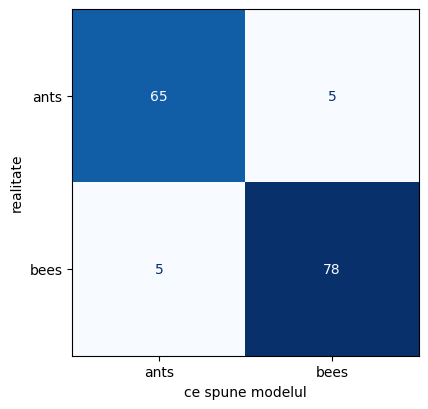

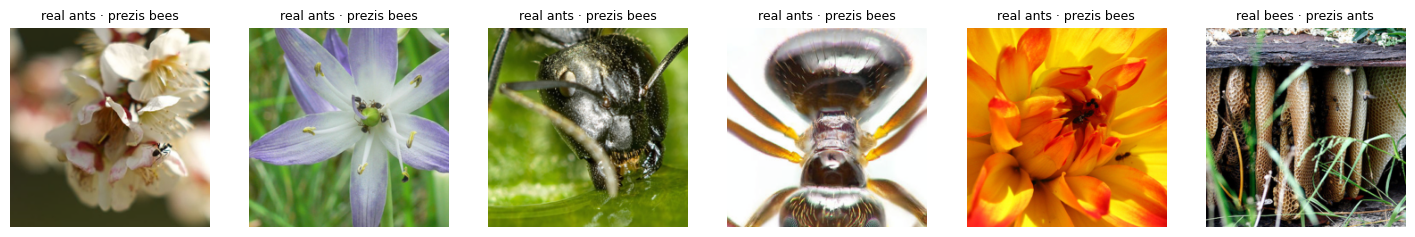

In [12]:
from sklearn.metrics import ConfusionMatrixDisplay
acc, y_true, y_pred = evalueaza(model_ft, val_loader)
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=CLASE, cmap="Blues", colorbar=False)
plt.xlabel("ce spune modelul")
plt.ylabel("realitate")
plt.show()

gresite = np.where(y_true != y_pred)[0][:6]
if len(gresite):
    fig, axe = plt.subplots(1, len(gresite), figsize=(3 * len(gresite), 3), squeeze=False)
    for ax, i in zip(axe[0], gresite):
        arata_tensor(date_val[i][0], ax, f"real {CLASE[y_true[i]]} · prezis {CLASE[y_pred[i]]}")
    plt.show()

**🤔 Întrebare** · Uită-te la pozele greșite. Ce au în comun? Ce ai face ca să le prinzi?

> ✍️ *Răspunsul tău:* ....

## 7 · Salvăm modelul și îl folosim pe poze noi 💾

Salvăm **greutățile** și **lista de clase**. Ca să facem o predicție, poza nouă trece prin **aceeași** preprocesare ca validarea (`transform_val`).

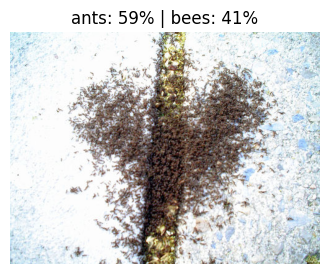

'ants'

In [13]:
torch.save({"greutati": model_ft.state_dict(), "clase": CLASE}, "model_furnici_albine.pt")

# ... mai târziu, în alt notebook sau într-o aplicație:
salvat = torch.load("model_furnici_albine.pt", map_location=device)
model_incarcat = models.resnet18(weights=None)
model_incarcat.fc = nn.Linear(model_incarcat.fc.in_features, len(salvat["clase"]))
model_incarcat.load_state_dict(salvat["greutati"])
model_incarcat = model_incarcat.to(device).eval()

def prezice(sursa):
    img = incarca_imagine(sursa)
    x = transform_val(img).unsqueeze(0).to(device)            # [1, 3, 224, 224]
    with torch.no_grad():
        p = model_incarcat(x).softmax(1)[0].cpu()
    plt.figure(figsize=(4, 4))
    plt.imshow(img)
    plt.axis("off")
    titlu = " | ".join(f"{c}: {pi:.0%}" for c, pi in zip(salvat["clase"], p))
    plt.title(titlu)
    plt.show()
    return salvat["clase"][p.argmax()]

prezice(date_val.imgs[0][0])

**Exercițiul 7.1 · Testează pe poze noi**

Caută pe internet o poză cu o furnică și una cu o albină și dă URL-urile la `prezice(...)`. Apoi încearcă o poză cu **un câine**. Ce răspunde modelul? De ce?

> ✍️ *Răspunsul tău:* ....

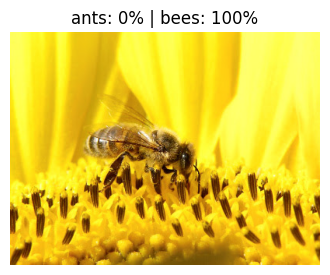

'bees'

In [14]:
prezice(date_val.imgs[-1][0])     # ✏️ înlocuiește cu un URL: prezice("https://...jpg")

## 8 · Proiectul tău în Google Colab 📋

În această secțiune vei adapta notebook-ul la **propriile tale poze**. Lucrează exact în ordinea de mai jos. Dacă încă nu ai pozele pregătite, poți exersa mai întâi cu `hymenoptera_data`.

### Înainte să rulezi codul

1. Deschide notebook-ul în **Google Colab**. Din meniu alege `Runtime` → `Change runtime type` → `T4 GPU` → `Save`.
2. Pregătește un folder cu această structură. Numele folderelor sunt etichetele pe care modelul le va învăța:

```text
/content/proiectul_meu/
├── train/
│   ├── clasa_1/   # poze folosite pentru antrenare
│   └── clasa_2/
└── val/
    ├── clasa_1/   # poze păstrate pentru verificare
    └── clasa_2/
```

3. Pune aproximativ 80% din poze în `train` și 20% în `val`. Nu pune aceeași poză în ambele foldere. Ideal: cel puțin 50–100 de poze pentru fiecare clasă.
4. În Colab, încarcă folderul sau arhiva ZIP în `/content/`, apoi scrie calea corectă în prima setare din celula următoare. Dacă folosești Google Drive, calea va începe de obicei cu `/content/drive/MyDrive/`.

### Ce vei face cu celula următoare

- schimbi **doar setările de sus**;
- verifici dacă notebook-ul vede clasele și numărul de poze;
- alegi feature extraction, apoi poți încerca fine-tuning;
- compari acuratețea de validare și te uiți la greșeli.

### Celula de lucru: schimbă doar secțiunea SETĂRI PROIECT

In [15]:
# PASUL 1 — SETĂRI: schimbă doar valorile din această zonă.
CALE_DATE = "/content/proiectul_meu"  # calea către folderul care conține train/ și val/
ARHITECTURA = "resnet18"             # lasă resnet18 la prima rulare
STRATEGIE = "feature_extraction"     # prima încercare; apoi încearcă "fine_tuning"
EPOCI = 3                              # numărul de treceri prin toate pozele de train

# PASUL 2 — VERIFICĂ STRUCTURA DATELOR.
# ImageFolder citește numele folderelor ca nume de clase.
date_train_proiect = datasets.ImageFolder(f"{CALE_DATE}/train")
date_val_proiect = datasets.ImageFolder(f"{CALE_DATE}/val")

CLASE_PROIECT = date_train_proiect.classes
print("Clase găsite:", CLASE_PROIECT)
print("Poze pentru antrenare:", len(date_train_proiect))
print("Poze pentru validare:", len(date_val_proiect))

# PASUL 3 — CONSTRUIEȘTE MODELUL PRE-ANTRENAT.
# Înlocuim ultimul strat cu unul care are exact câte clase ai tu.
def model_adaptat(nume, nr_clase, strategie):
    greutati = models.get_model_weights(nume).DEFAULT
    model = models.get_model(nume, weights=greutati)

    # Feature extraction: păstrăm straturile învățate și antrenăm doar capul.
    # Fine-tuning: permitem și straturilor modelului să se adapteze.
    for parametru in model.parameters():
        parametru.requires_grad = (strategie == "fine_tuning")

    if hasattr(model, "fc"):  # ResNet
        model.fc = nn.Linear(model.fc.in_features, nr_clase)
    else:  # EfficientNet sau MobileNet
        model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, nr_clase)

    return model, greutati.transforms()

model_proiect, transformare_model = model_adaptat(
    ARHITECTURA, len(CLASE_PROIECT), STRATEGIE
)

# PASUL 4 — PREGĂTEȘTE POZELE PENTRU MODEL.
# La train folosim augmentare; la validare doar transformarea standard.
transformare_train = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transformare_model,
])

train_dataset = datasets.ImageFolder(
    f"{CALE_DATE}/train", transform=transformare_train
)
val_dataset = datasets.ImageFolder(
    f"{CALE_DATE}/val", transform=transformare_model
)

train_loader_proiect = torch.utils.data.DataLoader(
    train_dataset, batch_size=16, shuffle=True
)
val_loader_proiect = torch.utils.data.DataLoader(
    val_dataset, batch_size=32
)

# PASUL 5 — ANTRENEAZĂ ȘI VERIFICĂ MODELUL.
# Dacă ai puține poze, începe cu feature extraction.
rata_invatare = 1e-3 if STRATEGIE == "feature_extraction" else 1e-4
model_proiect = antreneaza(
    model_proiect,
    train_loader_proiect,
    epoci=EPOCI,
    lr=rata_invatare,
    val_loader=val_loader_proiect,
)

acuratete, _, _ = evalueaza(model_proiect, val_loader_proiect)
print(f"Acuratețea finală pe validare: {acuratete:.1%}")

FileNotFoundError: [Errno 2] No such file or directory: '/content/proiectul_meu/train'

**Provocare (opțional) · Altă arhitectură**

Schimbă `ARHITECTURA` în `"efficientnet_b0"` sau `"mobilenet_v3_large"` și rulează șablonul. Compară acuratețea și durata cu ResNet18.

> ✍️ *Răspunsul tău:* ....

## Recap 🎓

- **Set propriu** = foldere `train/val/<clasa>/` (`ImageFolder`) sau CSV + `Dataset` propriu.
- **Augmentare** doar pe train, și doar transformări plauzibile pentru problema ta.
- **Transfer learning**: model pre-antrenat + cap nou cu `nr_clase` ieșiri.
  - **Feature extraction**: înghețat tot, antrenezi doar capul (puține date).
  - **Fine-tuning**: dezghețat ultimul bloc (sau tot), `lr` mic (mai multe date / poze diferite).
- **Predicție**: aceeași preprocesare ca la validare; modelul știe doar clasele tale.